# Consumer Complaint Classification

End-to-end NLP pipeline that predicts the product category of a customer's written complaint. It compares **SimpleRNN, LSTM and GRU** (built from scratch in Keras) against a **fine-tuned DistilBERT** (Hugging Face).

**Notebook outline**
1. Setup and data loading
2. Data cleaning
3. Class distribution and text length
4. Train / validation / test split and class weights
5. Tokenization and padding
6. SimpleRNN, LSTM and GRU from scratch
7. Fine-tuning DistilBERT
8. Model comparison and error analysis
9. Classifying new complaints
10. Final results

> DistilBERT was fine-tuned on a GPU in Google Colab (about 31 minutes for 3 epochs). The SimpleRNN, LSTM and GRU runs take only a few minutes.

## 1. Setup and data loading

Load the [Consumer Complaints Dataset for NLP](https://www.kaggle.com/datasets/shashwatwork/consume-complaints-dataset-fo-nlp) from Kaggle and fix the random seed for reproducibility.


In [ ]:
!pip install -q kagglehub

import kagglehub, pandas as pd, numpy as np, random, os
import tensorflow as tf

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

path = kagglehub.dataset_download("shashwatwork/consume-complaints-dataset-fo-nlp")
print(os.listdir(path))

Using Colab cache for faster access to the 'consume-complaints-dataset-fo-nlp' dataset.
['complaints_processed.csv']


Inspect the raw data: shape, columns, first rows and missing values.


In [ ]:
csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
df = pd.read_csv(os.path.join(path, csv_file))

print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df.isna().sum())

(162421, 3)
['Unnamed: 0', 'product', 'narrative']
   Unnamed: 0           product  \
0           0       credit_card   
1           1       credit_card   
2           2    retail_banking   
3           3  credit_reporting   
4           4  credit_reporting   

                                           narrative  
0  purchase order day shipping amount receive pro...  
1  forwarded message date tue subject please inve...  
2  forwarded message cc sent friday pdt subject f...  
3  payment history missing credit report speciali...  
4  payment history missing credit report made mis...  
Unnamed: 0     0
product        0
narrative     10
dtype: int64


## 2. Data cleaning

The text in this dataset is **already preprocessed** (lowercase, no punctuation or numbers, no stop words, lemmatized), so no further text cleaning is needed for training. The `clean_text` function defined later in the notebook reproduces the same preprocessing for new complaints.

Here we clean the *rows*: remove empty narratives, exact duplicates, and texts that appear with conflicting labels (these cannot be learned and would leak between splits).

In [ ]:
df = df.drop(columns=["Unnamed: 0"])

# 1) null / empty
print("Null narratives:", df["narrative"].isna().sum())
df = df.dropna(subset=["narrative"])
df["narrative"] = df["narrative"].astype(str).str.strip()
df = df[df["narrative"] != ""]

# 2) exact duplicate rows (same text + same label)
n0 = len(df)
df = df.drop_duplicates(subset=["narrative", "product"])
print("Removed exact duplicates:", n0 - len(df))

# 3) conflicting labels (same text, different labels) -> remove all of them
label_counts = df.groupby("narrative")["product"].nunique()
conflicting = label_counts[label_counts > 1].index
print("Conflicting texts:", len(conflicting))
df = df[~df["narrative"].isin(conflicting)].reset_index(drop=True)

print("Final shape:", df.shape)

Null narratives: 10
Removed exact duplicates: 37735
Conflicting texts: 172
Final shape: (124300, 2)


## 3. Class distribution and text length

The classes are imbalanced: `credit_reporting` is about 45% of the data. We also look at the number of words per complaint to choose the sequence length.

product
credit_reporting       56172
debt_collection        20998
mortgages_and_loans    18701
credit_card            14963
retail_banking         13466
Name: count, dtype: int64
product
credit_reporting       45.19
debt_collection        16.89
mortgages_and_loans    15.05
credit_card            12.04
retail_banking         10.83
Name: count, dtype: float64


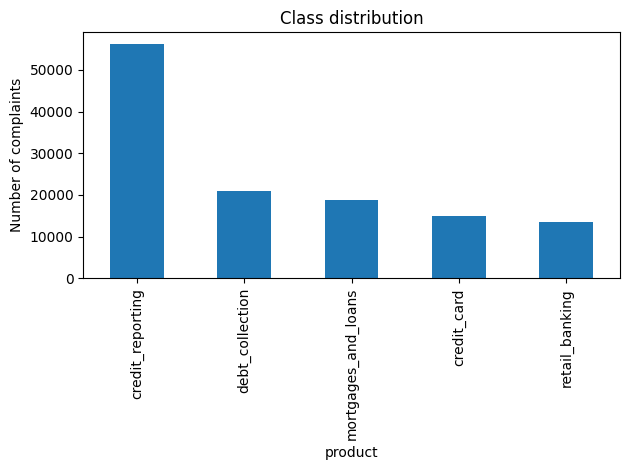

count    124300.000000
mean         87.212663
std         110.978938
min           1.000000
50%          58.000000
75%         104.000000
90%         180.000000
95%         253.000000
99%         502.000000
max        2685.000000
Name: n_words, dtype: float64


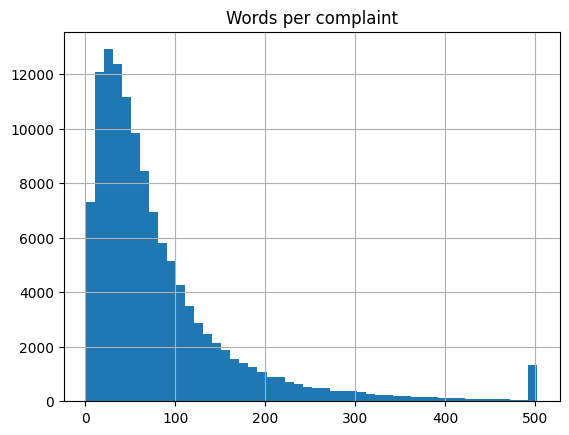

In [ ]:
import matplotlib.pyplot as plt

counts = df["product"].value_counts()
print(counts)
print((counts / len(df) * 100).round(2))

counts.plot(kind="bar", title="Class distribution")
plt.ylabel("Number of complaints"); plt.tight_layout(); plt.show()

df["n_words"] = df["narrative"].str.split().str.len()
print(df["n_words"].describe(percentiles=[.5, .75, .9, .95, .99]))

df["n_words"].clip(upper=df["n_words"].quantile(.99)).hist(bins=50)
plt.title("Words per complaint"); plt.show()

## 4. Train / validation / test split and class weights

Stratified 80/10/10 split, so each split keeps the same class proportions. To handle the imbalance, class weights are computed from the **training set only** and used in the loss function.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

le = LabelEncoder()
df["label"] = le.fit_transform(df["product"])
class_names = list(le.classes_)
NUM_CLASSES = len(class_names)
print(dict(enumerate(class_names)))

train_df, temp_df = train_test_split(
    df, test_size=0.20, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

print(len(train_df), len(val_df), len(test_df))
print(train_df["label"].value_counts(normalize=True).round(3).sort_index())
print(test_df["label"].value_counts(normalize=True).round(3).sort_index())

# class weights from TRAIN only
weights = compute_class_weight("balanced",
                               classes=np.arange(NUM_CLASSES),
                               y=train_df["label"])
class_weight = dict(enumerate(weights))
print(class_weight)

{0: 'credit_card', 1: 'credit_reporting', 2: 'debt_collection', 3: 'mortgages_and_loans', 4: 'retail_banking'}
99440 12430 12430
label
0    0.120
1    0.452
2    0.169
3    0.150
4    0.108
Name: proportion, dtype: float64
label
0    0.120
1    0.452
2    0.169
3    0.150
4    0.108
Name: proportion, dtype: float64
{0: np.float64(1.6614870509607351), 1: np.float64(0.44256531220793094), 2: np.float64(1.1839504702940826), 3: np.float64(1.329322906222846), 4: np.float64(1.8460967232897056)}


## 5. Tokenization and padding

Convert text to integer sequences with the Keras `Tokenizer` (vocabulary of 30,000 words, out-of-vocabulary token) and pad or truncate every complaint to 250 tokens. The last line shows how much text is lost to truncation.

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_SIZE = 30000
MAX_LEN = 250

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["narrative"])

def encode(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding="post", truncating="post")

X_train = encode(train_df["narrative"]); y_train = train_df["label"].values
X_val   = encode(val_df["narrative"]);   y_val   = val_df["label"].values
X_test  = encode(test_df["narrative"]);  y_test  = test_df["label"].values

print(X_train.shape, X_val.shape, X_test.shape)
print("Total vocab found:", len(tokenizer.word_index))

# how much text we lose by truncation
lens = train_df["narrative"].str.split().str.len()
print("Truncated texts: %.1f%%" % ((lens > MAX_LEN).mean() * 100))

(99440, 250) (12430, 250) (12430, 250)
Total vocab found: 41669
Truncated texts: 5.1%


In [ ]:
print("build_model" in globals(), "train_and_eval" in globals())
print("X_train" in globals(), "class_weight" in globals())

False False
True True


## 6. Models built from scratch

All three recurrent models share the same architecture: `Embedding (128-d)` → recurrent layer (128 units) → `Dropout` → `Dense (64)` → `Dropout` → `Dense (5, softmax)`. Only the recurrent layer changes. Training uses class weights, early stopping on validation loss, and reports accuracy, precision, recall, F1 and a confusion matrix.

### 6.1 SimpleRNN

Model: "simple_rnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,881,477 (14.81 MB)

 Trainable params: 3,881,477 (14.81 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
389/389 - 26s - 67ms/step - accuracy: 0.5743 - loss: 0.9877 - val_accuracy: 0.6931 - val_loss: 0.8904
Epoch 2/15
389/389 - 13s - 32ms/step - accuracy: 0.7516 - loss: 0.7337 - val_accuracy: 0.7335 - val_loss: 0.7950
Epoch 3/15
389/389 - 12s - 30ms/step - accuracy: 0.7946 - loss: 0.6370 - val_accuracy: 0.8002 - val_loss: 0.6070
Epoch 4/15
389/389 - 21s - 53ms/step - accuracy: 0.7930 - loss: 0.6324 - val_accuracy: 0.7927 - val_loss: 0.6671
Epoch 5/15
389/389 - 12s - 30ms/step - accuracy: 0.7964 - loss: 0.6157 - val_accuracy: 0.7662 - val_loss: 0.7561
Epoch 6/15
389/389 - 12s - 30ms/step - accuracy: 0.8072 - loss: 0.5756 - val_accuracy: 0.7767 - val_loss: 0.6723
                     precision    recall  f1-score   support

        credit_card     0.7198    0.6847    0.7018      1497
   credit_reporting     0.8804    0.8293    0.8541      5617
    debt_collection     0.6802    0.7819    0.7275      2100
mortgages_and_loans     0.8155    0.7422    0.7772      1870
     retail_bank

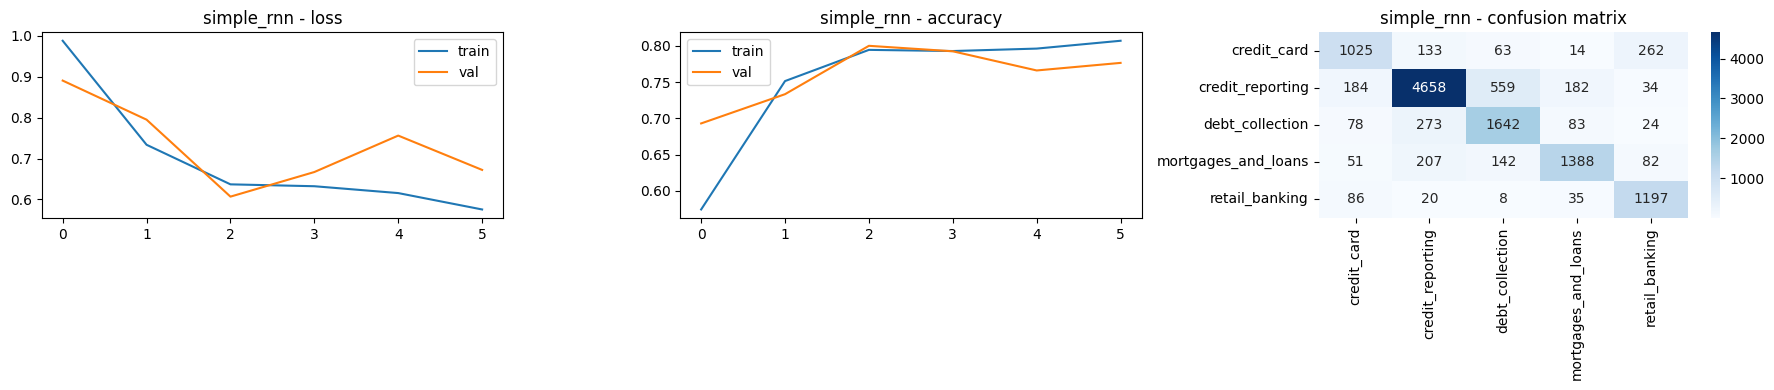

In [ ]:
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix
import time, seaborn as sns, matplotlib.pyplot as plt

class_weight = {k: float(v) for k, v in class_weight.items()}
results = {}

def build_model(rnn_layer, name):
    model = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, 128, mask_zero=True),
        rnn_layer,
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"])
    return model

def train_and_eval(model, name, epochs=15, batch_size=256):
    es = callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                 restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=epochs, batch_size=batch_size,
                     class_weight=class_weight, callbacks=[es], verbose=2)
    train_min = (time.time() - t0) / 60

    t0 = time.time()
    probs = model.predict(X_test, batch_size=512, verbose=0)
    infer_ms = (time.time() - t0) / len(X_test) * 1000
    preds = probs.argmax(axis=1)

    results[name] = {
        "accuracy": accuracy_score(y_test, preds),
        "macro_f1": f1_score(y_test, preds, average="macro"),
        "weighted_f1": f1_score(y_test, preds, average="weighted"),
        "params_M": model.count_params() / 1e6,
        "train_min": train_min,
        "infer_ms_per_sample": infer_ms,
    }

    print(classification_report(y_test, preds, target_names=class_names, digits=4))

    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    ax[0].plot(hist.history["loss"], label="train")
    ax[0].plot(hist.history["val_loss"], label="val")
    ax[0].set_title(f"{name} - loss"); ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="train")
    ax[1].plot(hist.history["val_accuracy"], label="val")
    ax[1].set_title(f"{name} - accuracy"); ax[1].legend()
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[2],
                xticklabels=class_names, yticklabels=class_names)
    ax[2].set_title(f"{name} - confusion matrix")
    plt.tight_layout(); plt.show()

    model.save(f"{name}.keras")
    return preds

# ---- SimpleRNN ----
model_rnn = build_model(layers.SimpleRNN(128), "simple_rnn")
model_rnn.summary()
preds_rnn = train_and_eval(model_rnn, "simple_rnn")


### 6.2 LSTM and 6.3 GRU

Epoch 1/15
389/389 - 21s - 54ms/step - accuracy: 0.7172 - loss: 0.7841 - val_accuracy: 0.8123 - val_loss: 0.5843
Epoch 2/15
389/389 - 9s - 23ms/step - accuracy: 0.8239 - loss: 0.5279 - val_accuracy: 0.8179 - val_loss: 0.5506
Epoch 3/15
389/389 - 9s - 24ms/step - accuracy: 0.8418 - loss: 0.4666 - val_accuracy: 0.8185 - val_loss: 0.5567
Epoch 4/15
389/389 - 9s - 24ms/step - accuracy: 0.8507 - loss: 0.4243 - val_accuracy: 0.8169 - val_loss: 0.5416
Epoch 5/15
389/389 - 11s - 29ms/step - accuracy: 0.8633 - loss: 0.3853 - val_accuracy: 0.8188 - val_loss: 0.5383
Epoch 6/15
389/389 - 9s - 23ms/step - accuracy: 0.8683 - loss: 0.3615 - val_accuracy: 0.8170 - val_loss: 0.5432
Epoch 7/15
389/389 - 9s - 24ms/step - accuracy: 0.8744 - loss: 0.3369 - val_accuracy: 0.8198 - val_loss: 0.5335
Epoch 8/15
389/389 - 9s - 24ms/step - accuracy: 0.8814 - loss: 0.3127 - val_accuracy: 0.8240 - val_loss: 0.5256
Epoch 9/15
389/389 - 9s - 24ms/step - accuracy: 0.8885 - loss: 0.2899 - val_accuracy: 0.8282 - val_los

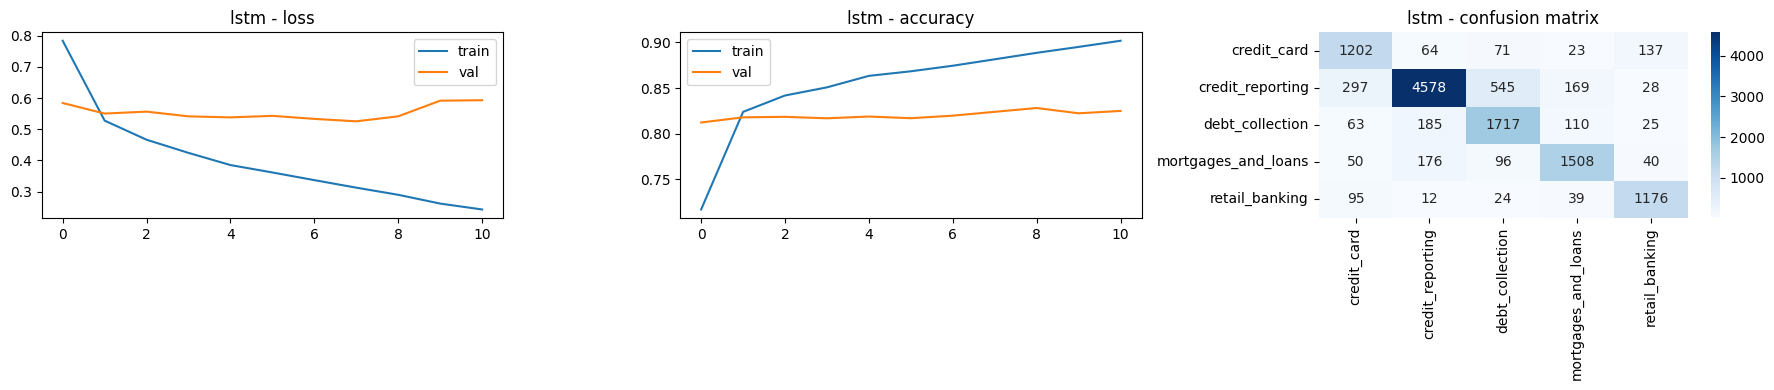

Epoch 1/15
389/389 - 11s - 28ms/step - accuracy: 0.7059 - loss: 0.7623 - val_accuracy: 0.8341 - val_loss: 0.4865
Epoch 2/15
389/389 - 9s - 23ms/step - accuracy: 0.8362 - loss: 0.4547 - val_accuracy: 0.8295 - val_loss: 0.4834
Epoch 3/15
389/389 - 10s - 26ms/step - accuracy: 0.8541 - loss: 0.3914 - val_accuracy: 0.8272 - val_loss: 0.4799
Epoch 4/15
389/389 - 9s - 22ms/step - accuracy: 0.8663 - loss: 0.3529 - val_accuracy: 0.8316 - val_loss: 0.4910
Epoch 5/15
389/389 - 9s - 23ms/step - accuracy: 0.8763 - loss: 0.3204 - val_accuracy: 0.8311 - val_loss: 0.4842
Epoch 6/15
389/389 - 9s - 23ms/step - accuracy: 0.8864 - loss: 0.2891 - val_accuracy: 0.8256 - val_loss: 0.5183
                     precision    recall  f1-score   support

        credit_card     0.7453    0.8290    0.7849      1497
   credit_reporting     0.9421    0.7821    0.8547      5617
    debt_collection     0.6932    0.8510    0.7640      2100
mortgages_and_loans     0.7801    0.8765    0.8255      1870
     retail_banking 

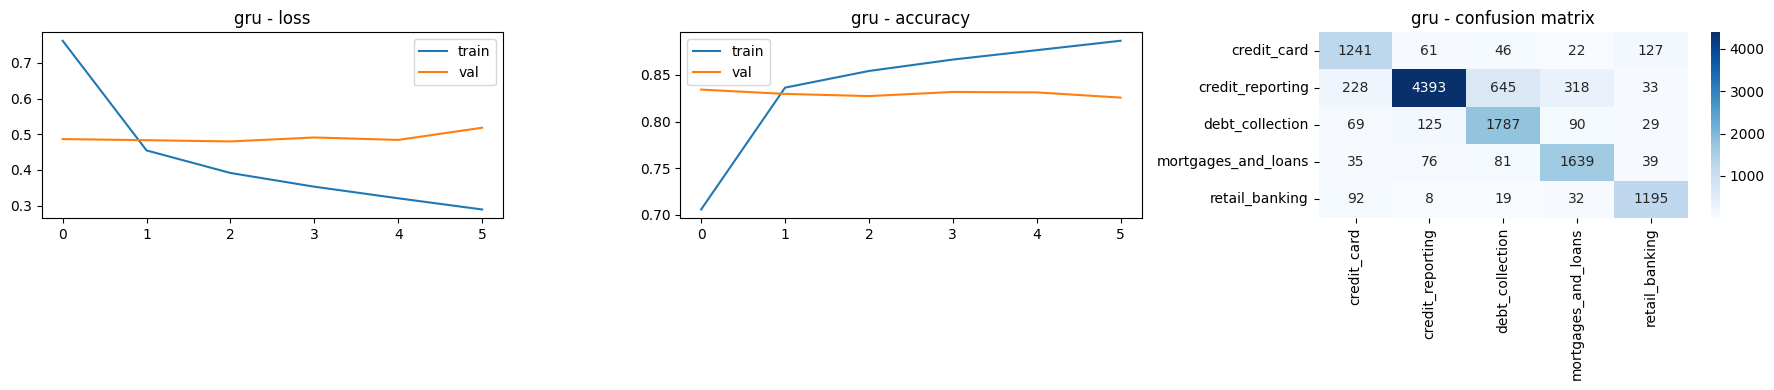

In [ ]:
# ---- LSTM ----
model_lstm = build_model(layers.LSTM(128), "lstm")
preds_lstm = train_and_eval(model_lstm, "lstm")

# ---- GRU ----
model_gru = build_model(layers.GRU(128), "gru")
preds_gru = train_and_eval(model_gru, "gru")

Save the tokenizer, label names and the results so far.

In [ ]:
import json, pickle
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
with open("labels.json", "w") as f:
    json.dump(class_names, f)

pd.DataFrame(results).T.round(4).to_csv("results_so_far.csv")
print(pd.DataFrame(results).T.round(4))

            accuracy  macro_f1  weighted_f1  params_M  train_min  \
simple_rnn    0.7973    0.7747       0.7983    3.8815     1.5864   
lstm          0.8191    0.8063       0.8215    3.9802     1.9320   
gru           0.8250    0.8184       0.8275    3.9477     0.9447   

            infer_ms_per_sample  
simple_rnn               0.1245  
lstm                     0.0447  
gru                      0.0451  


## 7. Fine-tuning DistilBERT

Prepare the Hugging Face datasets (max length 256), the model `distilbert-base-uncased` with 5 labels, and a `WeightedTrainer` that applies the same class weights to the cross-entropy loss. Validation accuracy and macro-F1 are tracked during training.

In [ ]:
import torch, torch.nn as nn
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, Trainer, TrainingArguments)

MODEL_NAME = "distilbert-base-uncased"
hf_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_ds(d):
    ds = Dataset.from_dict({"text": d["narrative"].tolist(),
                            "label": d["label"].tolist()})
    return ds.map(lambda b: hf_tokenizer(b["text"], truncation=True, max_length=256),
                  batched=True, remove_columns=["text"])

train_ds, val_ds, test_ds = to_ds(train_df), to_ds(val_df), to_ds(test_df)
collator = DataCollatorWithPadding(hf_tokenizer)

model_bert = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_CLASSES,
    id2label=dict(enumerate(class_names)),
    label2id={n: i for i, n in enumerate(class_names)})

class_weights_t = torch.tensor([class_weight[i] for i in range(NUM_CLASSES)],
                               dtype=torch.float)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = nn.CrossEntropyLoss(weight=class_weights_t.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro")}

In [ ]:
import torch, torch.nn as nn
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, Trainer, TrainingArguments)

MODEL_NAME = "distilbert-base-uncased"
hf_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_ds(d):
    ds = Dataset.from_dict({"text": d["narrative"].tolist(),
                            "label": d["label"].tolist()})
    return ds.map(lambda b: hf_tokenizer(b["text"], truncation=True, max_length=256),
                  batched=True, remove_columns=["text"])

train_ds, val_ds, test_ds = to_ds(train_df), to_ds(val_df), to_ds(test_df)
collator = DataCollatorWithPadding(hf_tokenizer)

model_bert = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_CLASSES,
    id2label=dict(enumerate(class_names)),
    label2id={n: i for i, n in enumerate(class_names)})

class_weights_t = torch.tensor([class_weight[i] for i in range(NUM_CLASSES)],
                               dtype=torch.float)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = nn.CrossEntropyLoss(weight=class_weights_t.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro")}

Train for 3 epochs (learning rate 2e-5, batch size 32, best checkpoint chosen by validation macro-F1), then evaluate on the same test set with the same metrics as the other models.

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.445057,0.424204,0.845615,0.835376
2,0.380023,0.388582,0.858568,0.848603


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.445057,0.424204,0.845615,0.835376
2,0.380023,0.388582,0.858568,0.848603
3,0.298478,0.395534,0.861545,0.852321


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

                     precision    recall  f1-score   support

        credit_card     0.7850    0.8317    0.8077      1497
   credit_reporting     0.9319    0.8497    0.8889      5617
    debt_collection     0.7652    0.8257    0.7943      2100
mortgages_and_loans     0.8088    0.8775    0.8418      1870
     retail_banking     0.8655    0.9175    0.8907      1346

           accuracy                         0.8550     12430
          macro avg     0.8313    0.8604    0.8447     12430
       weighted avg     0.8603    0.8550    0.8562     12430



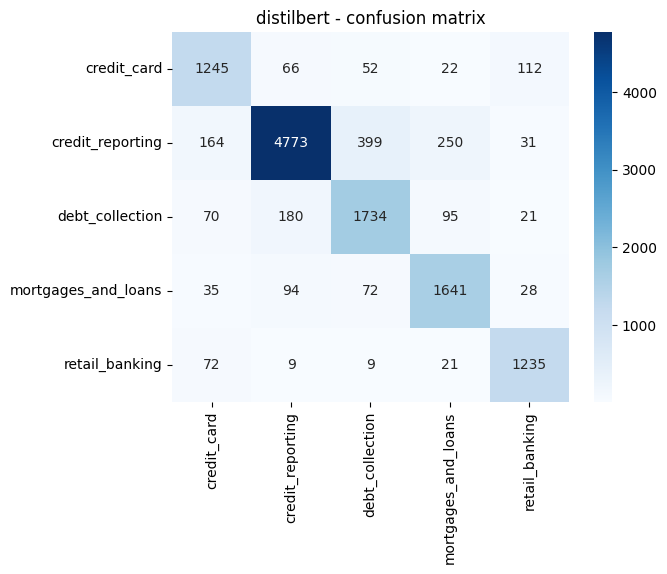

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

            accuracy  macro_f1  weighted_f1  params_M  train_min  \
simple_rnn    0.7973    0.7747       0.7983    3.8815     1.5864   
lstm          0.8191    0.8063       0.8215    3.9802     1.9320   
gru           0.8250    0.8184       0.8275    3.9477     0.9447   
distilbert    0.8550    0.8447       0.8562   66.9573    30.8033   

            infer_ms_per_sample  
simple_rnn               0.1245  
lstm                     0.0447  
gru                      0.0451  
distilbert               2.0063  


In [ ]:
args = TrainingArguments(
    output_dir="distilbert_out",
    eval_strategy="epoch", save_strategy="epoch",
    learning_rate=2e-5, weight_decay=0.01, warmup_steps=900,
    per_device_train_batch_size=32, per_device_eval_batch_size=64,
    num_train_epochs=3, fp16=True,
    load_best_model_at_end=True, metric_for_best_model="macro_f1",
    save_total_limit=1, report_to="none", seed=SEED)

trainer = WeightedTrainer(model=model_bert, args=args,
                          train_dataset=train_ds, eval_dataset=val_ds,
                          data_collator=collator, compute_metrics=compute_metrics)

t0 = time.time()
trainer.train()
train_min = (time.time() - t0) / 60

# ---- test evaluation, same metrics as the other models ----
t0 = time.time()
out = trainer.predict(test_ds)
infer_ms = (time.time() - t0) / len(test_ds) * 1000
preds_bert = out.predictions.argmax(-1)

results["distilbert"] = {
    "accuracy": accuracy_score(y_test, preds_bert),
    "macro_f1": f1_score(y_test, preds_bert, average="macro"),
    "weighted_f1": f1_score(y_test, preds_bert, average="weighted"),
    "params_M": sum(p.numel() for p in model_bert.parameters()) / 1e6,
    "train_min": train_min,
    "infer_ms_per_sample": infer_ms,
}
print(classification_report(y_test, preds_bert, target_names=class_names, digits=4))

cm = confusion_matrix(y_test, preds_bert)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("distilbert - confusion matrix"); plt.show()

trainer.save_model("complaint_model")
hf_tokenizer.save_pretrained("complaint_model")
print(pd.DataFrame(results).T.round(4))

## 8. Model comparison and error analysis

Compare accuracy, macro-F1 and inference time across the four models, list the most frequent confusions of the best model, and look at a sample of misclassified complaints.

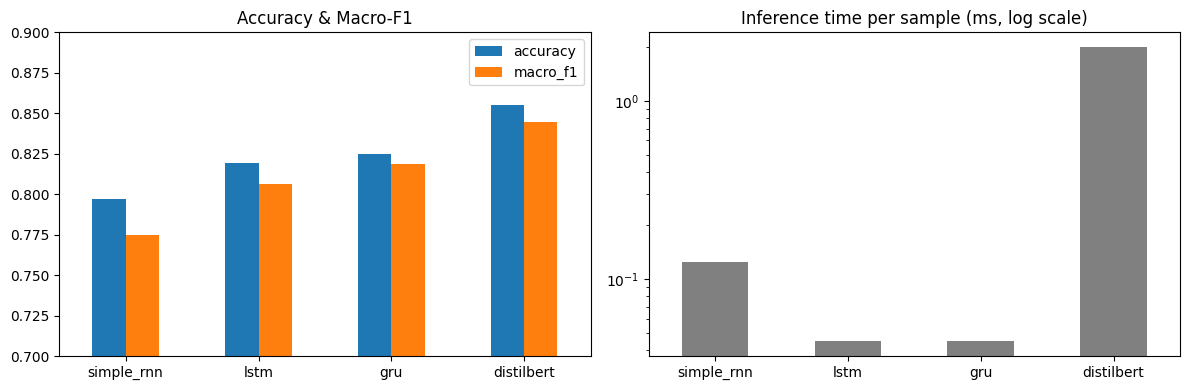

Top confusions (true -> predicted, count):
  credit_reporting -> debt_collection: 399
  credit_reporting -> mortgages_and_loans: 250
  debt_collection -> credit_reporting: 180
  credit_reporting -> credit_card: 164
  credit_card -> retail_banking: 112

Total errors: 1802
                   product              pred                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     narrative
7771   mortgages_and_loans  credit_reporting                                                                 

'/content/complaint_model_zip.zip'

In [ ]:
import shutil, json
from sklearn.metrics import confusion_matrix

# 1) save results + comparison chart
res = pd.DataFrame(results).T.round(4)
res.to_csv("results_final.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
res[["accuracy", "macro_f1"]].plot(kind="bar", ax=ax[0], ylim=(0.7, 0.9))
ax[0].set_title("Accuracy & Macro-F1"); ax[0].tick_params(axis="x", rotation=0)
res["infer_ms_per_sample"].plot(kind="bar", ax=ax[1], logy=True, color="gray")
ax[1].set_title("Inference time per sample (ms, log scale)")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig("model_comparison.png", dpi=150); plt.show()

# 2) most frequent confusions of the best model
cm = confusion_matrix(y_test, preds_bert)
pairs = [(class_names[i], class_names[j], cm[i, j])
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
pairs.sort(key=lambda x: -x[2])
print("Top confusions (true -> predicted, count):")
for t, p, c in pairs[:5]:
    print(f"  {t} -> {p}: {c}")

# 3) sample of misclassified complaints
errs = test_df.copy()
errs["pred"] = [class_names[i] for i in preds_bert]
errs = errs[errs["label"].values != preds_bert]
pd.set_option("display.max_colwidth", 300)
print("\nTotal errors:", len(errs))
print(errs[["product", "pred", "narrative"]].sample(8, random_state=SEED).to_string())

# 4) zip the deployment files for download
shutil.make_archive("complaint_model_zip", "zip", "complaint_model")

## 9. Classifying new complaints

`clean_text` applies the same preprocessing as the training data (lowercase, remove punctuation/numbers/special characters, remove stop words, lemmatize). It is needed for raw text typed by a user.

In [ ]:
import re, nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download("stopwords", quiet=True); nltk.download("wordnet", quiet=True)

STOP = set(stopwords.words("english"))
lemm = WordNetLemmatizer()

def clean_text(text, lemmatize=True):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    words = [w for w in text.split() if w not in STOP]
    if lemmatize:
        words = [lemm.lemmatize(w) for w in words]
    return " ".join(words)

raw = "I called Capital One 3 times on 05/12/2020!!! They NEVER fixed the wrong charge on my account."
print("RAW  :", raw)
print("CLEAN:", clean_text(raw))

sample = train_df["narrative"].sample(2000, random_state=SEED)
print(f"Identical after re-cleaning: {(sample == sample.apply(clean_text)).mean():.1%}")

RAW  : I called Capital One 3 times on 05/12/2020!!! They NEVER fixed the wrong charge on my account.
CLEAN: called capital one time never fixed wrong charge account
Identical after re-cleaning: 97.0%


Use the best model (DistilBERT) to predict the category and confidence score of new complaints.

In [ ]:
import torch
model_bert.eval()

def predict_complaint(text):
    inputs = hf_tokenizer(clean_text(text), truncation=True, max_length=256,
                          return_tensors="pt").to(model_bert.device)
    with torch.no_grad():
        probs = torch.softmax(model_bert(**inputs).logits, dim=-1)[0].cpu().numpy()
    return {class_names[i]: float(p) for i, p in enumerate(probs)}

new_complaints = [
    "A debt collector keeps calling me about a loan I already paid off and threatens to sue.",
    "There is an incorrect late payment on my credit report and the bureau refuses to remove it.",
    "My bank charged me overdraft fees even though my account had enough money.",
    "I was approved for a mortgage but the lender keeps delaying the closing and changed the rate.",
]
for c in new_complaints:
    p = predict_complaint(c)
    top = max(p, key=p.get)
    print(f"{top} ({p[top]:.1%}) <- {c[:70]}...")

debt_collection (98.1%) <- A debt collector keeps calling me about a loan I already paid off and ...
credit_reporting (93.4%) <- There is an incorrect late payment on my credit report and the bureau ...
retail_banking (99.2%) <- My bank charged me overdraft fees even though my account had enough mo...
mortgages_and_loans (99.4%) <- I was approved for a mortgage but the lender keeps delaying the closin...


Sanity check: look at the few training texts that `clean_text` still changes, to confirm it matches the dataset's preprocessing.

In [ ]:
diff = sample[sample != sample.apply(clean_text)].head(5)
for t in diff:
    print("DATA :", t[:150])
    print("OURS :", clean_text(t)[:150])
    print()

DATA : please help middle real estate transaction loan ca close lender unable obtain equifax credit profile score good surpass minimum thresh hold loan lende
OURS : please help middle real estate transaction loan ca close lender unable obtain equifax credit profile score good surpass minimum thresh hold loan lende

DATA : beginning receive notice escrow amount mortgage would changing error reduced payment amount auto bill pay new amount resulted payment le short change 
OURS : beginning receive notice escrow amount mortgage would changing error reduced payment amount auto bill pay new amount resulted payment le short change 

DATA : mortgage bank america escrow set account always paid tax insurance county two property tax installment one due one due county sent notice due coronavi
OURS : mortgage bank america escrow set account always paid tax insurance county two property tax installment one due one due county sent notice due coronavi

DATA : applied loan month payment covid started a

## 10. Final results

Final comparison table for the four models (test set, 12,430 complaints).

**Best model: DistilBERT.** It improves on the best from-scratch model (GRU) in accuracy and macro-F1, at the cost of many more parameters and a much longer training and inference time. The model is published at [mai-data-ai/complaint-distilbert](https://huggingface.co/mai-data-ai/complaint-distilbert) and deployed with Gradio at [mai-data-ai/complaint-classifier](https://huggingface.co/spaces/mai-data-ai/complaint-classifier).

In [ ]:
from sklearn.metrics import precision_score, recall_score

all_preds = {"simple_rnn": preds_rnn, "lstm": preds_lstm,
             "gru": preds_gru, "distilbert": preds_bert}

for name, p in all_preds.items():
    results[name]["macro_precision"] = precision_score(y_test, p, average="macro")
    results[name]["macro_recall"]    = recall_score(y_test, p, average="macro")

final = pd.DataFrame(results).T[["accuracy", "macro_precision", "macro_recall",
                                 "macro_f1", "params_M", "train_min",
                                 "infer_ms_per_sample"]].round(4)
print(final)
final.to_csv("results_final.csv")

            accuracy  macro_precision  macro_recall  macro_f1  params_M  \
simple_rnn    0.7973           0.7689        0.7855    0.7747    3.8815   
lstm          0.8191           0.7938        0.8231    0.8063    3.9802   
gru           0.8250           0.8001        0.8453    0.8184    3.9477   
distilbert    0.8550           0.8313        0.8604    0.8447   66.9573   

            train_min  infer_ms_per_sample  
simple_rnn     1.5864               0.1245  
lstm           1.9320               0.0447  
gru            0.9447               0.0451  
distilbert    30.8033               2.0063  
